# P8. 계산으로 사후 구하기: 격자 근사와 MCMC

**목표**
- 켤레가 없을 때 사후를 숫자로 구하는 가장 쉬운 방법(격자 근사)과 그 한계(모수가 늘면 칸 수가 폭발)를 봅니다.
- Metropolis 알고리즘을 직접 짜서, "제안하고 → 사후 높이를 비교해 받거나 거절하는" 걸음이 사후 분포를 그려 내는 것을 봅니다.
- trace 그림, warm-up(앞부분 버리기), 걸음 크기, 여러 사슬과 $\hat R$ 로 "제대로 섞였나"를 확인합니다.
- 시퀀싱: VAF 300 개로 purity, subclone 의 CCF, subclone 비율 세 모수를 한꺼번에 MCMC 로 구합니다.

**이 노트북이 답하는 질문**: 모수가 여러 개라 식으로 풀 수 없을 때, 사후는 어떻게 구하나?

**같이 볼 강의·교재**
- McElreath, *Statistical Rethinking* 2023, 8강 "MCMC" (4주차, 7–9장) [5]
- Downey, *Think Bayes* 2판, 19장 "MCMC" [6]
- BDA3, 11.2 절(Metropolis), 11.4 절(수렴 확인) [1]
- Harvard Stat 110, 31–33강 "Markov Chains" (MCMC 가 쓰는 마르코프 연쇄의 기초) [7]

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 뜻 고정 — 사전 하늘, 우도 주황, 사후 파랑, 증거 진회색, 핵심 자주
import logging, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats, special

warnings.filterwarnings("ignore", category=RuntimeWarning)
COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           highlight="#CC79A7", ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB",
           ok="#009E73", alt="#D55E00", ref="#9CA3AF", shade="#F3F4F6")

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 아래 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:                                          # 이름표가 조각보다 넓으면 그만큼 자리를 더 준다
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2                            # 가운데 정렬
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        t = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                    bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                              alpha=0.25 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                              linewidth=1.0))
        boxes[k] = t
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {}
    for k, t in boxes.items():                             # 상자 크기(축 좌표)
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv)
        ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        ca, cb = ((ax0 + ax1) / 2, (ay0 + ay1) / 2), ((bx0 + bx1) / 2, (by0 + by1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def phred_to_e(q):
    """Phred 점수 → 오류 확률: Q = -10 log10(e) [Cock 2010]"""
    return 10 ** (-np.asarray(q, float) / 10)

apply_theme()

In [2]:
# 이 노트북의 그림 함수와 계산 도구
def logbinom_kernel(x, n, v):
    """이항 로그 우도에서 v 에 따라 변하는 부분만: x log v + (n-x) log(1-v)"""
    v = np.clip(v, 1e-12, 1 - 1e-12)
    return x * np.log(v) + (n - x) * np.log1p(-v)

def draw_grid_1d(x=6, n=20, sizes=(5, 12, 200)):
    exact_th = np.linspace(0, 1, 801); exact = stats.beta.pdf(exact_th, 1 + x, 1 + n - x)
    fig, axs = plt.subplots(1, len(sizes), figsize=(12, 3.5), sharey=True, gridspec_kw={"wspace": 0.12})
    for ax, k in zip(axs, sizes):
        g = np.linspace(0, 1, k); post = stats.binom.pmf(x, n, g); post = post / post.sum()
        dens = post / (g[1] - g[0])                            # 칸 넓이로 나눠 밀도 눈금으로
        ax.plot(exact_th, exact, color=COL["muted"], lw=1, ls=":")
        ax.bar(g, dens, width=(g[1] - g[0]) * 0.9, color=COL["posterior"], alpha=0.55, lw=0)
        ax.set_xlabel(r"$\theta$"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
        panel(ax, "ABC"[list(sizes).index(k)], f"{k} grid points")
    note(axs[0], 0.98, 0.95, "dotted = exact Beta(7, 15)", ha="right", va="top", transform=axs[0].transAxes, color=COL["ink"])
    callout(axs[0], 0.98, 0.7, "too coarse:\nshape is distorted", ha="right", va="top", transform=axs[0].transAxes, fontsize=9.5)
    plt.show()

def simulate_vaf(n_mut=300, depth=60, purity=0.6, ccf_sub=0.4, w_sub=0.3, seed=0):
    """이배체 종양의 변이 VAF: 클론성(CCF 1)과 subclone(CCF ccf_sub) 섞임. 기대 VAF = purity × CCF / 2"""
    rng = np.random.default_rng(seed)
    sub = rng.random(n_mut) < w_sub
    dp = rng.poisson(depth, n_mut)
    vaf = purity * np.where(sub, ccf_sub, 1.0) / 2
    alt = rng.binomial(dp, vaf)
    return alt, dp, sub

def mix_loglik(alt, dp, p, f, w):
    """모수 배열(p, f, w)이 들어오면 브로드캐스팅으로 한꺼번에 계산. 변이 축은 마지막."""
    p, f, w = (np.asarray(t, float)[..., None] for t in (p, f, w))
    l_c = logbinom_kernel(alt, dp, p / 2); l_s = logbinom_kernel(alt, dp, p * f / 2)
    m = np.maximum(l_c, l_s)
    return np.sum(m + np.log((1 - w) * np.exp(l_c - m) + w * np.exp(l_s - m)), axis=-1)

def draw_grid_2d(P, F, logpost, truth):
    post = np.exp(logpost - logpost.max()); post /= post.sum()
    fig = plt.figure(figsize=(10.5, 4.6))
    gs = fig.add_gridspec(2, 2, width_ratios=[3, 1], height_ratios=[1, 3], wspace=0.05, hspace=0.05)
    ax = fig.add_subplot(gs[1, 0]); axt = fig.add_subplot(gs[0, 0], sharex=ax); axr = fig.add_subplot(gs[1, 1], sharey=ax)
    cs = ax.contourf(P, F, post, levels=np.linspace(post.max() * 0.03, post.max(), 10), cmap="Blues")
    ax.contour(P, F, post, levels=[post.max() * 0.03], colors=[COL["posterior"]], linewidths=0.8)
    ax.plot(*truth, "x", color=COL["highlight"], ms=10, mew=2.2)
    note(ax, truth[0] + 0.004, truth[1] + 0.01, "truth", color=COL["highlight"], fontsize=9.5)
    ax.set_xlabel("purity p"); ax.set_ylabel("subclone CCF f")
    axt.fill_between(P[0], post.sum(0), color=COL["posterior"], alpha=0.3, lw=0); axt.plot(P[0], post.sum(0), color=COL["posterior"])
    axr.fill_betweenx(F[:, 0], post.sum(1), color=COL["posterior"], alpha=0.3, lw=0); axr.plot(post.sum(1), F[:, 0], color=COL["posterior"])
    for a in (axt, axr):
        a.set_axis_off()
    axt.set_title("Joint posterior on a 2-D grid (subclone share w fixed at 0.3); marginals on the sides", loc="left")
    plt.show()
    return post

def draw_curse(times):
    d = np.arange(1, 11); k = 100
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    ax.semilogy(d, float(k) ** d, "o-", color=COL["ink"], lw=1.8)
    for dd, t in times.items():
        ax.text(dd + 0.15, k ** dd / 3, f"{t:.2g} s " + ("measured" if dd < 3 else "(estimated: 100 x d=2)"),
                fontsize=9, va="top", color=COL["ink"])               # 점의 오른쪽 아래: 선은 오른쪽 위로 간다
    ax.axhline(1e12, color=COL["muted"], lw=0.8, ls=":"); note(ax, 1.1, 2e12, "10^12 points: hopeless", va="bottom")
    ax.set_ylim(3, None); ax.set_xlabel("number of parameters"); ax.set_ylabel("grid points (100 per parameter)"); ygrid(ax)
    panel(ax, "", "The curse of dimensionality: grid points = 100^d")
    callout(ax, 5.6, 1e3, "MCMC's cost also grows with d,\nbut far more slowly:\nit walks, it does not tile", ha="left", fontsize=9.5)
    plt.show()

def metropolis_1d(logpost, start, step, n_iter, rng):
    """Metropolis(BDA3 11.2 절): 대칭 제안(정규분포), r = p(θ*)/p(θ), min(r,1) 확률로 받음"""
    th = np.empty(n_iter); prop = np.empty(n_iter); acc = np.zeros(n_iter, bool)
    cur, lp = start, logpost(start)
    for t in range(n_iter):
        cand = cur + step * rng.standard_normal()
        lc = logpost(cand)
        prop[t] = cand
        if np.log(rng.random()) < lc - lp:
            cur, lp = cand, lc; acc[t] = True
        th[t] = cur
    return th, prop, acc

def logpost_vaf(t, x=6, n=20):
    """평평한 사전 + 이항 우도(상수 뺌). 0~1 밖은 확률 0"""
    if t <= 0 or t >= 1:
        return -np.inf
    return x * np.log(t) + (n - x) * np.log(1 - t)

def draw_walker(th, prop, acc, n_show=40):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.25})
    ax = axs[0]
    grid = np.linspace(0.001, 0.999, 400); dens = stats.beta.pdf(grid, 7, 15)
    ax.fill_betweenx(grid, n_show + 2 + dens * 3, n_show + 2, color=COL["posterior"], alpha=0.2, lw=0)
    ax.plot(n_show + 2 + dens * 3, grid, color=COL["posterior"], lw=1.5)
    note(ax, n_show + 3, 0.62, "target\nposterior", color=COL["posterior"])
    steps = np.arange(n_show)
    ax.plot(steps, th[:n_show], "-", color=COL["muted"], lw=1.2)
    rej = ~acc[:n_show]
    ax.scatter(steps[rej], prop[:n_show][rej], marker="x", color=COL["alt"], s=28, zorder=3, label="rejected proposal")
    ax.scatter(steps[acc[:n_show]], th[:n_show][acc[:n_show]], color=COL["ok"], s=18, zorder=3, label="accepted move")
    ax.set_xlabel("step"); ax.set_ylabel(r"$\theta$"); ax.set_ylim(0, 0.8); ygrid(ax)
    ax.legend(loc="upper left")
    panel(ax, "A", f"The walker: first {n_show} steps")
    ax = axs[1]
    keep = th[len(th) // 2:]
    ax.hist(keep, bins=50, density=True, color=COL["posterior"], alpha=0.45)
    ax.plot(grid, dens, color=COL["ink"], lw=1.4, ls=":")
    ax.set_xlabel(r"$\theta$"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    panel(ax, "B", f"{keep.size:,} kept steps vs exact Beta(7,15)")
    callout(ax, 0.98, 0.95, "where the walker spends\nits time = the posterior", transform=ax.transAxes, ha="right", va="top", fontsize=9.5)
    plt.show()

def draw_step_sizes(runs):
    fig, axs = plt.subplots(len(runs), 1, figsize=(11.5, 2.2 * len(runs)), sharex=True, gridspec_kw={"hspace": 0.5})
    for ax, (step, (th, acc)) in zip(axs, runs.items()):
        ax.plot(th, color=COL["ink"], lw=0.7)
        ax.axvspan(0, len(th) // 2, color=COL["shade"], lw=0, zorder=0)
        ax.set_ylim(0, 1); ax.set_ylabel(r"$\theta$"); ygrid(ax)
        panel(ax, "ABC"[list(runs).index(step)], f"step size {step}: acceptance {acc.mean():.0%}")
    note(axs[0], 10, 0.1, "grey = warm-up (first half, discarded)", color=COL["ink"])
    callout(axs[0], 0.99, 0.85, "too small: stuck far from the target", transform=axs[0].transAxes, ha="right", va="top", fontsize=9.5)
    callout(axs[2], 0.99, 0.85, "too large: rejects almost every move", transform=axs[2].transAxes, ha="right", va="top", fontsize=9.5)
    axs[-1].set_xlabel("iteration")
    plt.show()

def split_rhat(chains):
    """BDA3 11.4 절: 앞쪽 절반(warm-up) 버리고, 남은 부분을 반으로 나눠 사슬 수를 두 배로. R = sqrt(var+ / W)"""
    chains = np.asarray(chains); n = chains.shape[1] // 2
    kept = chains[:, n:]
    half = kept.shape[1] // 2
    s = np.concatenate([kept[:, :half], kept[:, half:2 * half]], axis=0)
    m, nn = s.shape
    means = s.mean(1); B = nn * means.var(ddof=1); W = s.var(axis=1, ddof=1).mean()
    var_plus = (nn - 1) / nn * W + B / nn
    return np.sqrt(var_plus / W)

def draw_chains(short, long_):
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.18})
    cols = [COL["posterior"], COL["alt"], COL["ok"], COL["likelihood"]]
    for ax, (chs, title) in zip(axs, [(short, "short run"), (long_, "long run")]):
        for c, ch in zip(cols, chs):
            ax.plot(ch, color=c, lw=0.8, alpha=0.9)
        ax.axvspan(0, chs.shape[1] // 2, color=COL["shade"], lw=0, zorder=0)
        r = split_rhat(chs)
        ax.set_ylim(0, 1); ax.set_xlabel("iteration"); ygrid(ax)
        panel(ax, "AB"[0 if title == "short run" else 1], f"4 chains, {title}: R-hat = {r:.3f}")
    axs[0].set_ylabel(r"$\theta$")
    callout(axs[0], 0.98, 0.95, "chains disagree → R-hat > 1", transform=axs[0].transAxes, ha="right", va="top", fontsize=9.5)
    callout(axs[1], 0.98, 0.95, "chains overlap → R-hat ≈ 1", transform=axs[1].transAxes, ha="right", va="top", fontsize=9.5)
    plt.show()

def logit(x): return np.log(x) - np.log1p(-x)
def expit(z): return 1 / (1 + np.exp(-z))

def make_logpost_mix(alt, dp):
    def lp(z):
        """z = logit(p, f, w). 사전은 원래 눈금에서 평평 → logit 눈금에서는 야코비안 log[θ(1-θ)] 을 더함.
        식별을 위해 subclone 은 클론보다 작다(f < 1)는 조건을 이미 f ∈ (0,1) 로 둠."""
        th = expit(z)
        jac = np.sum(np.log(th) + np.log1p(-th))
        return mix_loglik(alt, dp, th[0], th[1], th[2]) + jac
    return lp

def metropolis_nd(lp, start, step, n_iter, rng):
    d = len(start); out = np.empty((n_iter, d)); acc = 0
    cur = np.array(start, float); lcur = lp(cur)
    for t in range(n_iter):
        cand = cur + step * rng.standard_normal(d)
        lc = lp(cand)
        if np.log(rng.random()) < lc - lcur:
            cur, lcur = cand, lc; acc += 1
        out[t] = cur
    return out, acc / n_iter

def draw_mix_results(alt, dp, chains, truth, names=("purity p", "subclone CCF f", "subclone share w")):
    fig = plt.figure(figsize=(12, 7.2))
    gs = fig.add_gridspec(3, 3, height_ratios=[1.1, 1, 1], hspace=0.65, wspace=0.28)
    ax = fig.add_subplot(gs[0, :])
    vaf = alt / dp
    ax.hist(vaf, bins=45, color=COL["none"], density=True)
    keep = np.concatenate([c[c.shape[0] // 2:] for c in chains])
    p, f, w = np.median(keep, axis=0)
    xs = np.linspace(0, 0.6, 300); dbar = dp.mean()
    for v, wt, c, lab in [(p / 2, 1 - w, COL["posterior"], "clonal"), (p * f / 2, w, COL["alt"], "subclonal")]:
        dens = wt * stats.norm.pdf(xs, v, np.sqrt(v * (1 - v) / dbar))
        ax.plot(xs, dens, color=c, lw=2); note(ax, v, dens.max() * 1.03, f"{lab}: VAF {v:.2f}", ha="center", color=c, va="bottom",
                                                  fontweight="semibold")
    ax.set_xlabel("observed VAF of 300 mutations"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_ylim(0, None); panel(ax, "A", "Data and the fitted two-cluster model (posterior medians)")
    cols = [COL["posterior"], COL["alt"], COL["ok"], COL["likelihood"]]
    for j in range(3):
        ax = fig.add_subplot(gs[1, j])
        for c, ch in zip(cols, chains):
            ax.plot(ch[:, j], color=c, lw=0.5, alpha=0.8)
        ax.axvspan(0, chains[0].shape[0] // 2, color=COL["shade"], lw=0, zorder=0)
        ax.axhline(truth[j], color=COL["highlight"], lw=1.2)
        ax.set_xticks([]); panel(ax, "BCD"[j], f"trace: {names[j]}")
        ax = fig.add_subplot(gs[2, j])
        ax.hist(keep[:, j], bins=40, color=COL["posterior"], alpha=0.5, density=True)
        ax.axvline(truth[j], color=COL["highlight"], lw=1.4)
        ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_xlabel(names[j])
        r = split_rhat(np.array([c[:, j] for c in chains]))
        panel(ax, "EFG"[j], f"posterior, R-hat {r:.3f}")
    fig.text(0.99, 0.015, "purple line = true value used in the simulation", ha="right", fontsize=9, color=COL["highlight"])
    plt.show()
    return keep

## 개념 지도

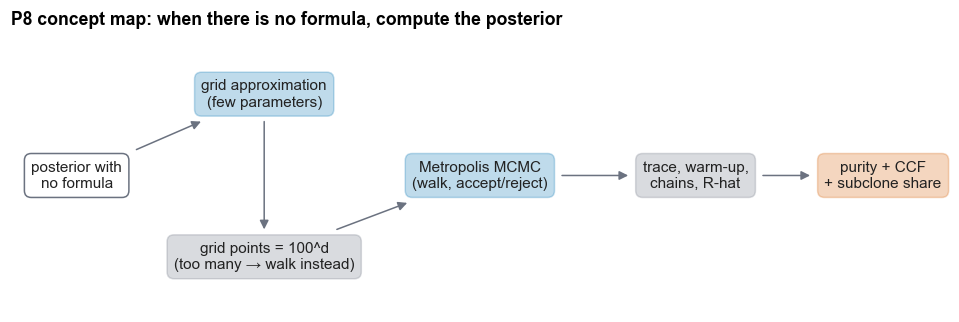

In [3]:
concept_map(
    {"q": (0.07, 0.5, "posterior with\nno formula", "white"),
     "grid": (0.27, 0.8, "grid approximation\n(few parameters)", COL["posterior"]),
     "curse": (0.27, 0.2, "grid points = 100^d\n(too many → walk instead)", COL["muted"]),
     "mcmc": (0.5, 0.5, "Metropolis MCMC\n(walk, accept/reject)", COL["posterior"]),
     "diag": (0.73, 0.5, "trace, warm-up,\nchains, R-hat", COL["muted"]),
     "seq": (0.93, 0.5, "purity + CCF\n+ subclone share", COL["alt"])},
    [("q", "grid", ""), ("grid", "curse", ""), ("curse", "mcmc", ""),
     ("mcmc", "diag", ""), ("diag", "seq", "")],
    title="P8 concept map: when there is no formula, compute the posterior")

**그림에서 볼 것**: 모수가 한두 개면 격자에서 사후를 직접 계산합니다. 모수가 늘면 격자 칸이 100 의 거듭제곱으로 늘어 불가능해지고, 그때 MCMC 로 사후에서 표본을 뽑습니다. MCMC 는 진단(trace, R-hat)과 짝을 이뤄야 믿을 수 있습니다.

## 먼저 알아 둘 것

**기호 사전**

| 기호·말 | 뜻 |
|---|---|
| 격자(grid) | θ 가 가질 수 있는 값을 촘촘히 늘어놓은 점들. 점마다 "사전 × 우도"를 계산 |
| 마르코프 연쇄 | 다음 값이 지금 값에만 기대는 무작위 걸음. Stat 110 31–33강 [7] |
| 제안(proposal) | 지금 자리에서 조금 떨어진 후보 자리 $\theta^*$ |
| $\min(r, 1)$ | r 과 1 중 작은 것. 받아들일 확률 |
| 정상 분포(stationary distribution) | 오래 걸은 뒤 "산책자가 어디쯤 있을지"의 분포가 더는 바뀌지 않게 된 분포. Metropolis 는 이것이 사후가 되도록 만든 걸음 [1] |
| warm-up | 출발점의 영향이 남은 앞부분. 버림 [1] |
| $\hat R$ | 아르햇. 여러 사슬이 같은 분포를 그리고 있는지 보는 수. 1 에 가까울수록 좋음 [1] |
| 유효 표본 수(effective sample size) | 앞뒤 표본이 서로 닮아 있는(자기상관) MCMC 표본 n 개가, 서로 독립인 표본 몇 개만큼의 정보인가 [1] |
| logit | $\log[\theta/(1-\theta)]$. 0~1 값을 −∞~+∞ 로 펴는 변환 |
| 야코비안(Jacobian) | 눈금을 바꿀 때 같은 폭이 늘거나 줄어드는 비율. 밀도를 새 눈금으로 옮길 때 곱해 줌 |

## 1. 격자 근사: 점마다 계산하고 합을 1 로

**한 줄 정의**: θ 의 가능한 값을 격자로 깔고, 점마다 "사전 × 우도"를 계산한 뒤 합이 1 이 되도록 나누면 사후의 근사입니다. P6 의 연속 사후가 이 방법이었습니다.

**왜 필요한가**: 켤레가 없는 모형에서도 모수가 한두 개면 이것이 가장 쉽고 정확합니다. 다만 BDA3 는 격자가 너무 성기면 사후의 상당 부분이 왜곡된다고 경고합니다 [1].

**숫자로 따라가기**: 평평한 사전, read 20 개 중 변이 6 개. 정답은 Beta(7, 15). 격자 점 5 개, 12 개, 200 개로 근사합니다.

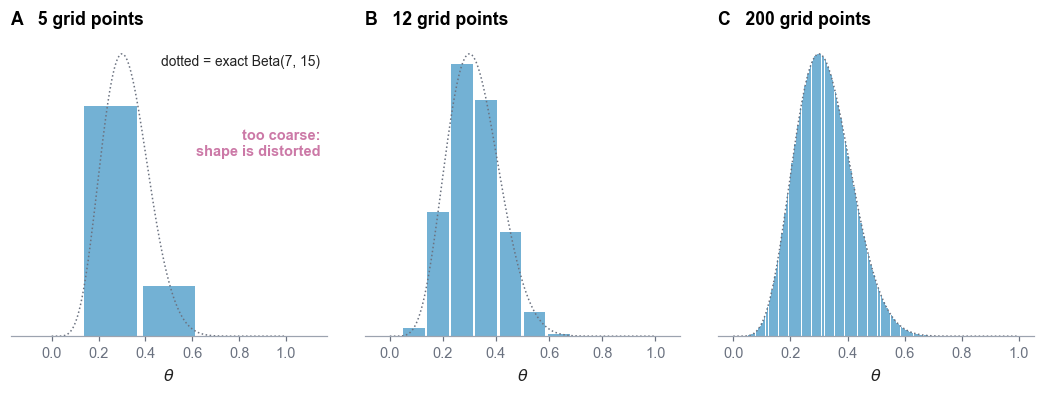

  5 points: posterior mean 0.2950  (exact 7/22 = 0.3182)
 12 points: posterior mean 0.3182  (exact 7/22 = 0.3182)
200 points: posterior mean 0.3182  (exact 7/22 = 0.3182)


In [4]:
draw_grid_1d()
for k in (5, 12, 200):
    g = np.linspace(0, 1, k); post = stats.binom.pmf(6, 20, g); post /= post.sum()
    print(f"{k:3d} points: posterior mean {np.sum(g * post):.4f}  (exact 7/22 = {7 / 22:.4f})")
g = np.linspace(0, 1, 200); post = stats.binom.pmf(6, 20, g); post /= post.sum()
assert abs(np.sum(g * post) - 7 / 22) < 1e-3

**그림에서 볼 것**: 파란 막대가 격자 근사, 점선이 정답 Beta(7, 15) 입니다. 점 5 개(A)는 모양이 뭉개지고, 12 개(B)는 대략 맞고, 200 개(C)는 정답과 겹칩니다. 평균도 위 출력처럼 점이 많을수록 7/22 에 가까워집니다.

## 2. 격자 2 차원: 모수 두 개를 함께

**한 줄 정의**: 모수가 두 개면 격자도 평면이 되고, 사후는 등고선 지도가 됩니다. 한 모수의 사후는 다른 모수 방향으로 더해서(주변화, marginalization) 얻습니다.

**시퀀싱 예**: 이배체 종양의 변이 300 개(깊이 60). 70% 는 클론성(CCF 1), 30% 는 subclone(CCF f) 입니다. VAF 의 기대값은 Dentro 2021 의 식 $\text{VAF} = \dfrac{CN_M\,\rho}{\rho\,CN_T + (1-\rho)\,CN_N}$ 에서 $CN_T = CN_N = 2$, 변이 copy 수 $CN_M = \text{CCF}$ 로 두면 $p\cdot\text{CCF}/2$ 입니다 [8]. 진짜 값 purity 0.6, f = 0.4 로 만들고, subclone 비율 w 는 0.3 으로 안다고 놓고 (p, f) 를 격자로 구합니다.

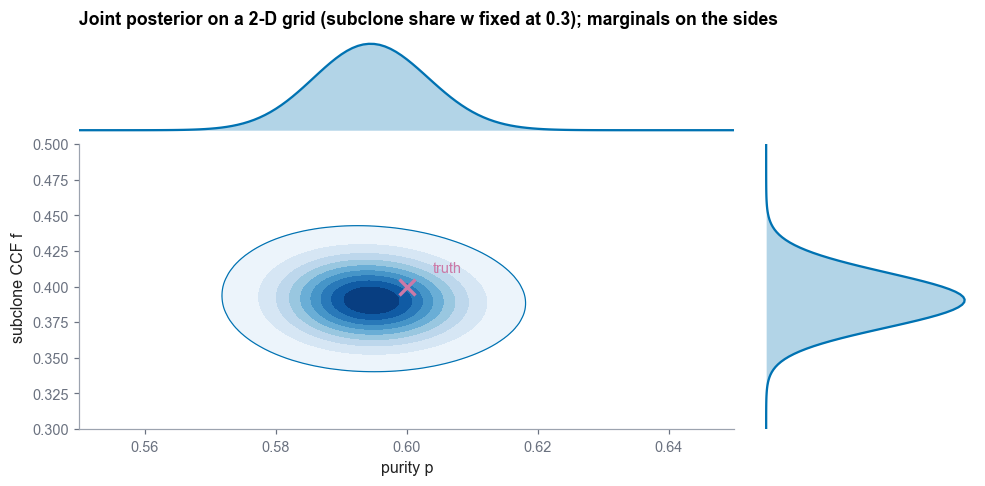

grid 13,431 points in 0.21 s; peak at purity 0.594, f 0.391


In [5]:
alt, dp, is_sub = simulate_vaf()
P, F = np.meshgrid(np.linspace(0.55, 0.65, 121), np.linspace(0.30, 0.50, 111))
import time
t0 = time.perf_counter(); logpost2 = mix_loglik(alt, dp, P, F, np.full_like(P, 0.3)); t2 = time.perf_counter() - t0
post2 = draw_grid_2d(P, F, logpost2, truth=(0.6, 0.4))
i_max = np.unravel_index(np.argmax(post2), post2.shape)
print(f"grid {P.size:,} points in {t2:.2f} s; peak at purity {P[i_max]:.3f}, f {F[i_max]:.3f}")
assert abs(P[i_max] - 0.6) < 0.03 and abs(F[i_max] - 0.4) < 0.06

**그림에서 볼 것**: 진한 파란 섬이 사후가 큰 곳이고, 자주색 × 가 진짜 값입니다. 위와 오른쪽 곡선은 각 모수의 주변 사후입니다. 섬이 비스듬히 기울어 있으면 두 모수가 서로 얽혀 있다는 뜻인데, 여기서는 섬이 거의 기울지 않았습니다. purity 가 클론 봉우리(VAF p/2)로 거의 정해지기 때문입니다.

## 3. 차원의 저주: 격자는 모수가 늘면 불가능해진다

**한 줄 정의**: 모수마다 100 칸이면 격자 점은 $100^d$ 개입니다. 모수 3 개면 100 만, 10 개면 $10^{20}$ 개입니다.

**왜 필요한가**: 실제 모형(여러 subclone, 구간마다 CN, 시료마다 purity)은 모수가 수십~수천 개입니다. 그래서 칸을 다 채우는 대신 **사후가 큰 곳을 걸어 다니며 표본을 모으는** 방법이 필요합니다.

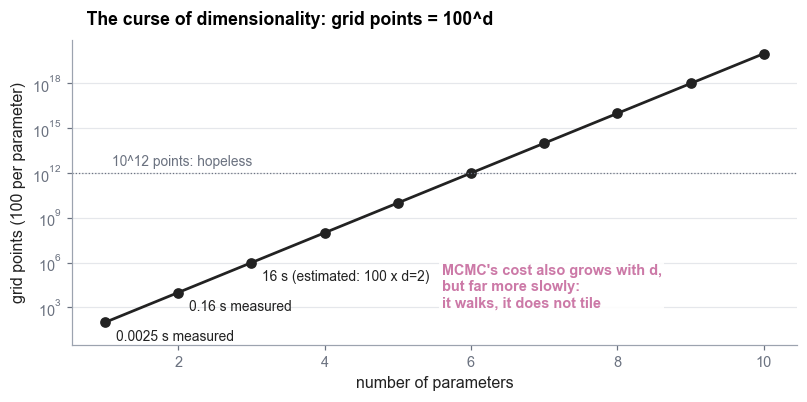

{1: '0.00251 s', 2: '0.155 s', 3: '15.5 s'} (d = 3 is extrapolated as 100 x d = 2)
grid points grew 100x from d = 1 to d = 2; measured time grew 62x


In [6]:
times = {}
for d_ in (1, 2):
    k = 100; t0 = time.perf_counter()
    if d_ == 1:
        mix_loglik(alt, dp, np.linspace(0.01, 0.99, k), np.full(k, 0.4), np.full(k, 0.3))
    else:
        Pp, Ff = np.meshgrid(np.linspace(0.01, 0.99, k), np.linspace(0.01, 0.99, k))
        mix_loglik(alt, dp, Pp, Ff, np.full_like(Pp, 0.3))
    times[d_] = time.perf_counter() - t0
times[3] = times[2] * 100                                     # 3 차원은 2 차원의 100 배(추정)
draw_curse(times)
print({k: f"{v:.3g} s" for k, v in times.items()}, "(d = 3 is extrapolated as 100 x d = 2)")
print(f"grid points grew 100x from d = 1 to d = 2; measured time grew {times[2] / times[1]:.0f}x")

**그림에서 볼 것**: 세로축이 로그 눈금입니다. 모수 하나 늘 때마다 칸이 100 배로 뜁니다. 잰 시간은 1 차원에서 2 차원으로 갈 때 위 출력의 배수만큼 늘었습니다. 칸이 100 배라고 시간이 꼭 100 배가 되지는 않습니다. 아주 작은 계산은 준비 비용이 커서 덜 늘고, 큰 배열은 메모리 때문에 더 늘 수 있습니다. 3 차원 값은 시간이 칸 수에 비례한다고 놓고 2 차원의 100 배로 잡은 대략적인 추정입니다. 점선 $10^{12}$ 위는 현실적으로 불가능한 영역입니다.

**MCMC 도 공짜는 아니다**: BDA3 12.2 절은 d 차원 정규분포 꼴의 사후에서 가장 효율적인 Metropolis 걸음 크기가 $c \approx 2.4/\sqrt d$ 이고, 그 효율(서로 독립인 표본에 견준 비율)이 약 $0.3/d$ 라고 적습니다 [1]. 모수가 늘면 같은 정밀도에 필요한 걸음 수도 대략 d 에 비례해 늘어납니다. 그래도 격자의 $100^d$ 보다는 훨씬 느리게 늡니다.

## 4. Metropolis: 사후 위를 걷는 산책자

**한 줄 정의**: Metropolis 알고리즘은 지금 자리 θ 에서 근처 후보 θ* 를 제안하고, 사후 높이의 비 $r = p(\theta^*\mid y)/p(\theta\mid y)$ 를 계산해, 확률 $\min(r, 1)$ 로 옮겨 가고 아니면 제자리에 머무는 걸음입니다 [1][2].

**왜 필요한가**: 이 비에서는 증거 $p(y)$ 가 분자·분모에 똑같이 있어서 지워집니다. 그래서 **사전 × 우도만 계산할 수 있으면** 됩니다. 오래 걸으면 산책자가 각 자리에 머무는 시간이 사후 확률에 비례합니다(BDA3 11.2 절은 목표 분포가 이 마르코프 연쇄의 정상 분포임을 보입니다 [1]). 정상 분포는 "충분히 오래 걸은 뒤 산책자가 어디쯤 있을지"의 분포가 더는 바뀌지 않게 된 상태입니다.

**알고리즘** (BDA3 11.2 절 [1])
1. 출발점 θ⁰ 을 고릅니다(사후가 0 이 아닌 곳).
2. t = 1, 2, … 마다
   - (a) 대칭인 분포(여기서는 정규분포)로 후보 θ* 를 뽑습니다.
   - (b) $r = p(\theta^*\mid y)/p(\theta^{t-1}\mid y)$ 를 계산합니다.
   - (c) 확률 $\min(r,1)$ 로 $\theta^t = \theta^*$, 아니면 $\theta^t = \theta^{t-1}$.

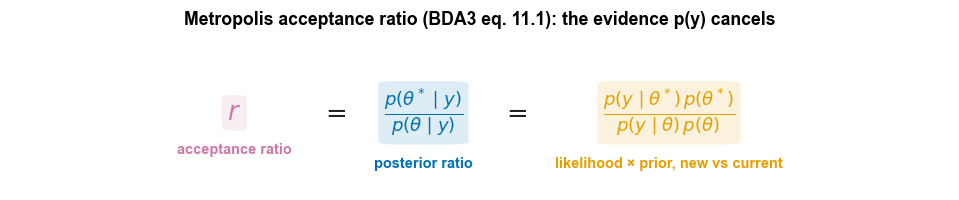

In [7]:
show_formula([
    (r"$r$", COL["highlight"], "acceptance ratio"),
    (r"$=$", None, None),
    (r"$\frac{p(\theta^*\mid y)}{p(\theta\mid y)}$", COL["posterior"], "posterior ratio"),
    (r"$=$", None, None),
    (r"$\frac{p(y\mid\theta^*)\,p(\theta^*)}{p(y\mid\theta)\,p(\theta)}$", COL["likelihood"], "likelihood × prior, new vs current"),
], title="Metropolis acceptance ratio (BDA3 eq. 11.1): the evidence p(y) cancels", height=1.8)

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\theta$ | 지금 자리 | 산책자가 서 있는 곳 | 아래 A 의 회색 선 |
| $\theta^*$ | 후보 자리 | 정규분포로 조금 옮긴 곳 | A 의 초록 점(받음)·빨간 ×(거절) |
| $r$ | 받아들임 비 | 후보가 더 높으면 r ≥ 1 → 늘 받음, 낮으면 r 의 확률로 받음 | — |
| $p(y)$ | 증거 | 분자·분모에 똑같이 있어 지워짐 → 계산할 필요 없음 | — |

**숫자로 따라가기**: 지금 θ = 0.30, 후보 θ* = 0.40 (6/20, 평평한 사전).
$r = \dfrac{0.4^{6}\,0.6^{14}}{0.3^{6}\,0.7^{14}} = (4/3)^6 (6/7)^{14} \approx 0.65$ → 65% 확률로 옮깁니다. 반대로 0.30 이 0.20 보다 높으므로, 0.20 에서 0.30 으로 가는 후보는 늘 받습니다.

r = 0.649


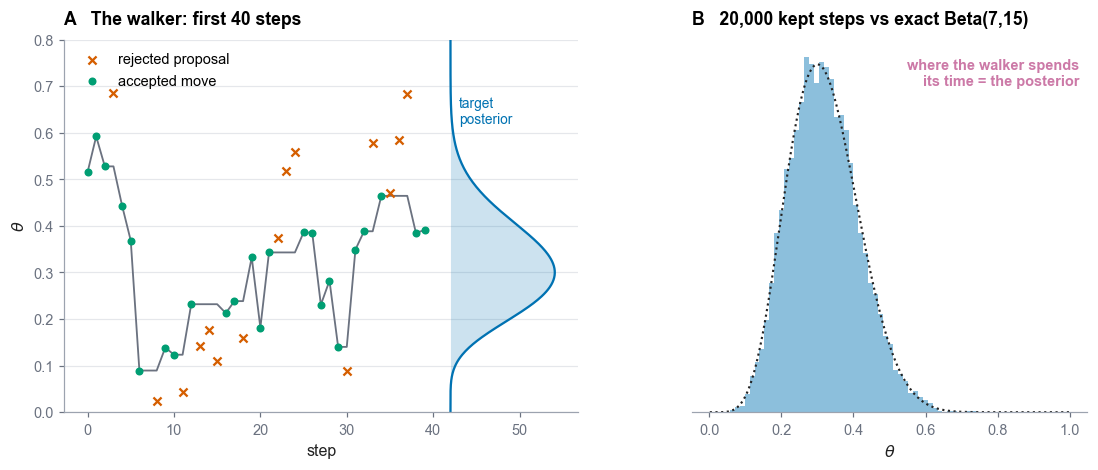

acceptance 65%; kept mean 0.3187 (exact 0.3182); 2.5%/97.5% [0.148 0.524] (exact [0.146 0.522])


In [8]:
r_example = np.exp(logpost_vaf(0.40) - logpost_vaf(0.30))
print(f"r = {r_example:.3f}")
assert abs(r_example - (0.4 ** 6 * 0.6 ** 14) / (0.3 ** 6 * 0.7 ** 14)) < 1e-12 and abs(r_example - 0.65) < 0.01
rng = np.random.default_rng(0)
th, prop, acc = metropolis_1d(logpost_vaf, start=0.5, step=0.12, n_iter=40_000, rng=rng)
draw_walker(th, prop, acc)
keep = th[len(th) // 2:]
print(f"acceptance {acc.mean():.0%}; kept mean {keep.mean():.4f} (exact {7 / 22:.4f}); "
      f"2.5%/97.5% {np.quantile(keep, [0.025, 0.975]).round(3)} (exact {stats.beta.ppf([0.025, 0.975], 7, 15).round(3)})")
assert abs(keep.mean() - 7 / 22) < 0.01
assert np.max(np.abs(np.quantile(keep, [0.025, 0.975]) - stats.beta.ppf([0.025, 0.975], 7, 15))) < 0.02

**그림에서 볼 것**
- A: 회색 선이 산책자의 길입니다. 초록 점은 받아들인 걸음, 빨간 × 는 거절된 후보입니다. 거절은 확률로 일어나서 어느 자리에서든 생길 수 있지만, 사후가 지금보다 낮은 후보일수록(예: 0.6 위, 0.1 아래) 거절될 가능성이 큽니다. 오른쪽에 목표 사후(파랑)를 옆으로 눕혀 그렸습니다.
- B: warm-up(앞쪽 절반)을 버린 2 만 걸음의 히스토그램이 정답 Beta(7, 15)(점선)와 겹칩니다. 평균과 95% 구간도 정답과 같습니다(위 출력).

**직접 바꿔 보기**: `start=0.95` 처럼 먼 곳에서 출발하거나 `step` 을 바꿔 보세요. 다음 절에서 이것을 체계적으로 봅니다.

In [9]:
# th2, prop2, acc2 = metropolis_1d(logpost_vaf, start=0.95, step=0.02, n_iter=2000, rng=np.random.default_rng(1)); draw_walker(th2, prop2, acc2)

## 5. trace 그림, warm-up, 걸음 크기

**한 줄 정의**: trace 그림은 걸음 번호에 따라 θ 를 그린 선입니다. 출발점의 흔적이 남은 앞부분은 버리는데(warm-up), BDA3 는 보수적으로 **앞쪽 절반을 버리는 것**을 기본으로 둡니다 [1].

**왜 필요한가**: 걸음 크기가 맞지 않으면 산책자가 사후를 제대로 돌지 못합니다. BDA3 는 좋은 제안 분포의 조건으로 "한 걸음이 적당한 거리를 가고(너무 작으면 느림), 너무 자주 거절되지 않을 것(너무 크면 제자리)"을 듭니다 [1]. 정규분포 꼴 사후라면 받아들임 비율이 1 차원에서 약 0.44, 모수가 많으면(대략 d > 5) 약 0.23 일 때 가장 효율적이라고 12.2 절은 적습니다 [1]. 4 절(걸음 크기 0.12)의 받아들임 비율과 견주어 보세요(위 출력).

**숫자로 따라가기**: 같은 사후(6/20)를 θ⁰ = 0.95 에서 출발해 걸음 크기 0.005, 0.15, 3 으로 2,000 걸음씩 걷습니다.

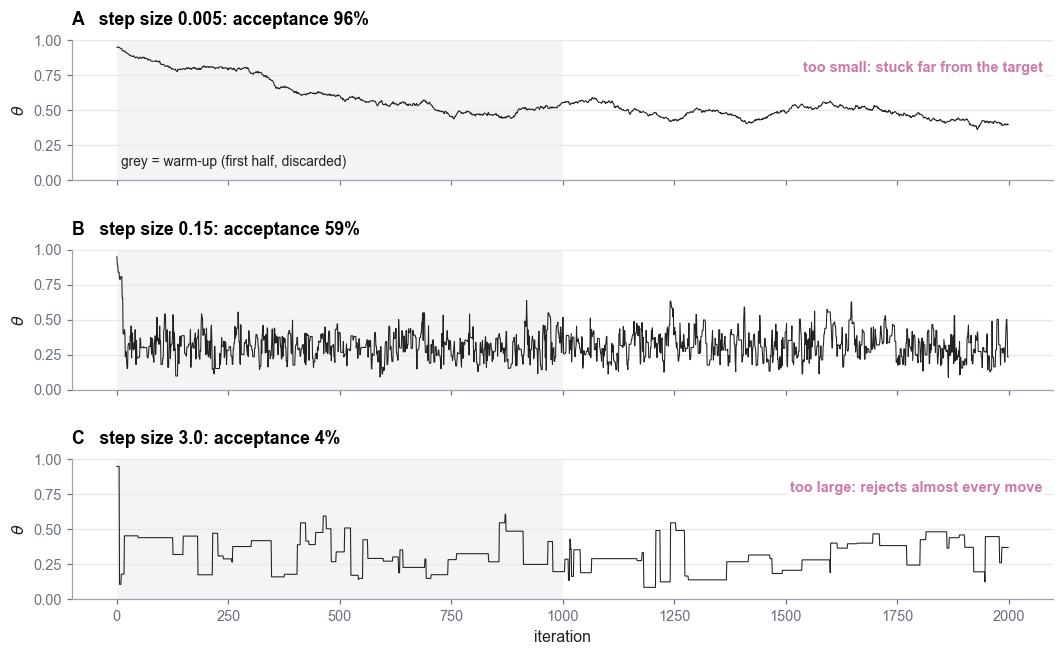

step 0.005: acceptance 96%, mean of kept half 0.481 (target 0.318)
step 0.15: acceptance 59%, mean of kept half 0.317 (target 0.318)
step 3.0: acceptance 4%, mean of kept half 0.305 (target 0.318)


In [10]:
runs = {}
for step, seed in [(0.005, 1), (0.15, 2), (3.0, 3)]:
    t_, p_, a_ = metropolis_1d(logpost_vaf, start=0.95, step=step, n_iter=2000, rng=np.random.default_rng(seed))
    runs[step] = (t_, a_)
draw_step_sizes(runs)
for step, (t_, a_) in runs.items():
    print(f"step {step}: acceptance {a_.mean():.0%}, mean of kept half {t_[1000:].mean():.3f} (target {7 / 22:.3f})")
assert runs[0.005][1].mean() > 0.9 and runs[3.0][1].mean() < 0.1
assert abs(runs[0.15][0][1000:].mean() - 7 / 22) < 0.03 and abs(runs[0.005][0][1000:].mean() - 7 / 22) > 0.1

**그림에서 볼 것**
- A (0.005): 거의 모든 걸음을 받지만 한 걸음이 너무 작아, 2,000 걸음이 지나도 0.95 에서 0.3 근처까지 내려오지 못합니다. 남긴 절반의 평균도 목표와 다릅니다(위 출력).
- B (0.15): 몇십 걸음 만에 내려와 0.15~0.5 사이를 고르게 돕니다. 이것이 좋은 trace 입니다("털 많은 애벌레" 모양).
- C (3): 후보가 거의 늘 0~1 밖이나 아주 낮은 곳이라 대부분 거절되고, 선이 계단처럼 오래 멈춥니다.
- 옅은 회색 구간(앞쪽 절반)이 warm-up 입니다.

## 6. 여러 사슬과 $\hat R$: 서로 다른 곳에서 출발해도 같은 곳에 모이나

**한 줄 정의**: 출발점을 일부러 흩어 놓은 사슬 여러 개를 돌리고, **사슬 사이 분산 B** 와 **사슬 안 분산 W** 를 비교합니다. 아직 섞이지 않았으면 B 가 커서 $\hat R$ 이 1 보다 큽니다 [1][3].

**식** (BDA3 11.4 절 식 (11.3)–(11.4) [1]): 각 사슬의 앞쪽 절반을 버리고, 남은 부분을 다시 반으로 나눠 사슬 수를 두 배로 만든 뒤

$$B = \frac{n}{m-1}\sum_j(\bar\psi_{\cdot j}-\bar\psi_{\cdot\cdot})^2,\quad W = \frac{1}{m}\sum_j s_j^2,\quad \widehat{\mathrm{var}}^+ = \frac{n-1}{n}W + \frac{1}{n}B,\quad \hat R = \sqrt{\widehat{\mathrm{var}}^+/W}$$

**얼마면 "1 에 가깝다"고 하나**
- BDA3 11.5 절: "we generally have been satisfied with setting 1.1 as a threshold". 그리고 $\hat R$ 이 1 근처이고 유효 표본 수가 사슬당 10 을 넘으면 표본을 모아 쓴다고 적습니다 [1].
- Vehtari 외 2021 은 순위 정규화로 고친 $\hat R$ 을 제안하며 더 엄격하게 $\hat R < 1.01$, 순위 정규화 유효 표본 수 > 400, 사슬은 기본 4 개 이상을 권합니다 [4]. 1.1 아래로 내려가도 아직 수렴하지 않은 예를 보았다는 것이 이유입니다.
- **유효 표본 수**: MCMC 표본은 앞뒤가 서로 닮아 있어서(자기상관), 표본 n 개가 서로 독립인 표본 n 개만큼의 정보를 주지 못합니다. 그 정보가 독립 표본 몇 개분인지가 유효 표본 수입니다(BDA3 11.5 절 [1]).

이 노트북의 assert 는 Vehtari 의 1.01 을 씁니다(아래 셀과 7 절).

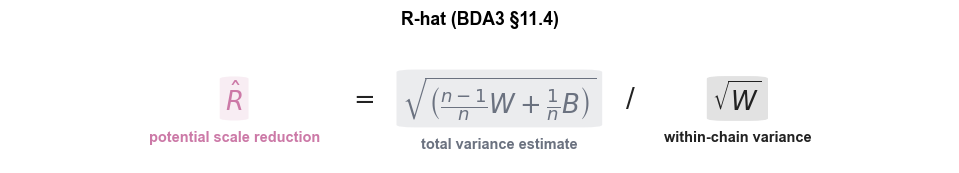

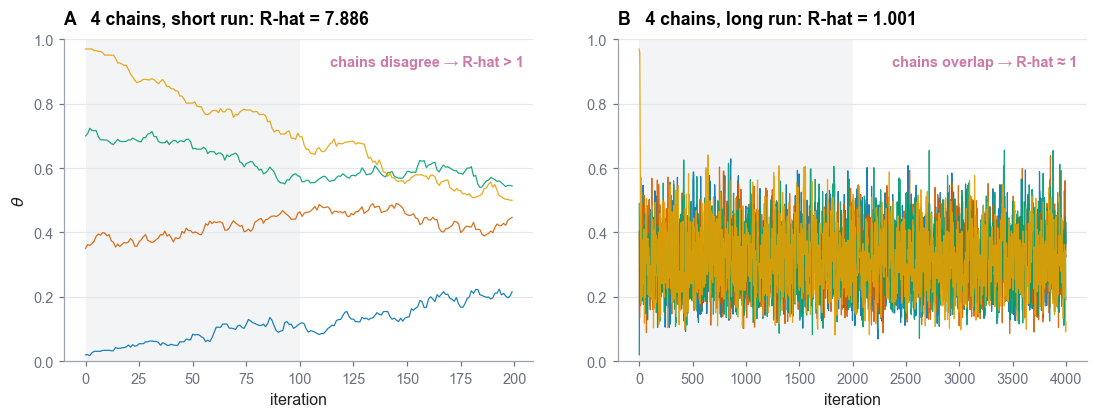

R-hat short run 7.886, long run 1.0012


In [11]:
show_formula([
    (r"$\hat R$", COL["highlight"], "potential scale reduction"),
    (r"$=$", None, None),
    (r"$\sqrt{\left(\frac{n-1}{n}W + \frac{1}{n}B\right)}$", COL["muted"], "total variance estimate"),
    (r"$/$", None, None),
    (r"$\sqrt{W}$", COL["ink"], "within-chain variance"),
], title="R-hat (BDA3 §11.4)")
starts = [0.02, 0.35, 0.7, 0.97]
short = np.array([metropolis_1d(logpost_vaf, s, 0.01, 200, np.random.default_rng(10 + i))[0] for i, s in enumerate(starts)])
long_ = np.array([metropolis_1d(logpost_vaf, s, 0.15, 4000, np.random.default_rng(20 + i))[0] for i, s in enumerate(starts)])
draw_chains(short, long_)
r_short, r_long = split_rhat(short), split_rhat(long_)
print(f"R-hat short run {r_short:.3f}, long run {r_long:.4f}")
assert r_short > 1.1 and r_long < 1.01

**그림에서 볼 것** (선 색은 사슬 네 개를 구분할 뿐, 사전·우도·사후의 색 뜻과는 상관없습니다): 왼쪽(걸음 크기 0.01, 200 걸음)은 네 사슬이 각자 출발점 근처에 머물러 서로 다른 곳을 그리고, $\hat R$ 이 1 보다 훨씬 큽니다. 오른쪽(0.15, 4,000 걸음)은 네 사슬이 같은 띠 안에서 겹치고 $\hat R \approx 1$ 입니다. "한 사슬만 보고 괜찮다"고 하면 왼쪽 같은 경우를 놓칩니다.

## 7. 시퀀싱: purity, subclone CCF, subclone 비율을 한꺼번에

**한 줄 정의**: 2 절의 변이 300 개에서 이번에는 w 도 모른다고 놓고, (p, f, w) 세 모수의 사후를 MCMC 로 구합니다.

**모형** (이 노트북의 장난감)
- 변이 i 의 변이 read 수: $x_i \sim (1-w)\,\mathrm{Binom}(d_i, p/2) + w\,\mathrm{Binom}(d_i, p f/2)$. 클론성 봉우리 VAF p/2, subclone 봉우리 VAF pf/2 [8].
- 사전: p, f, w 모두 0~1 에서 평평. f < 1 이라 두 봉우리가 뒤바뀌는 일이 없습니다.
- 걷기는 logit 눈금에서 합니다(0~1 경계에 부딪히지 않게). 원래 눈금에서 평평한 사전을 logit 눈금으로 옮기면 야코비안 $\log\theta(1-\theta)$ 을 더해야 합니다. 야코비안은 눈금을 바꿀 때 같은 폭이 늘거나 줄어드는 비율입니다. logit 눈금의 한 칸은 원래 눈금에서 폭이 $\theta(1-\theta)$ 라, 이 비율을 곱해야(로그로는 더해야) 원래 눈금의 평평한 사전이 그대로 유지됩니다.

**왜 필요한가**: 실제 clonality 도구가 푸는 문제가 이런 꼴입니다. 예를 들어 PCAWG 의 subclone 분석에서 PhylogicNDT 는 변이마다 purity 와 CN 을 반영한 CCF 확률 분포를 계산하고(ABSOLUTE), 그 분포들을 Dirichlet Process 로 군집해 군집 수까지 데이터에서 배운다고 설명됩니다 [9]. 군집 수를 고정한 이 장난감은 그 생각의 가장 작은 판입니다.

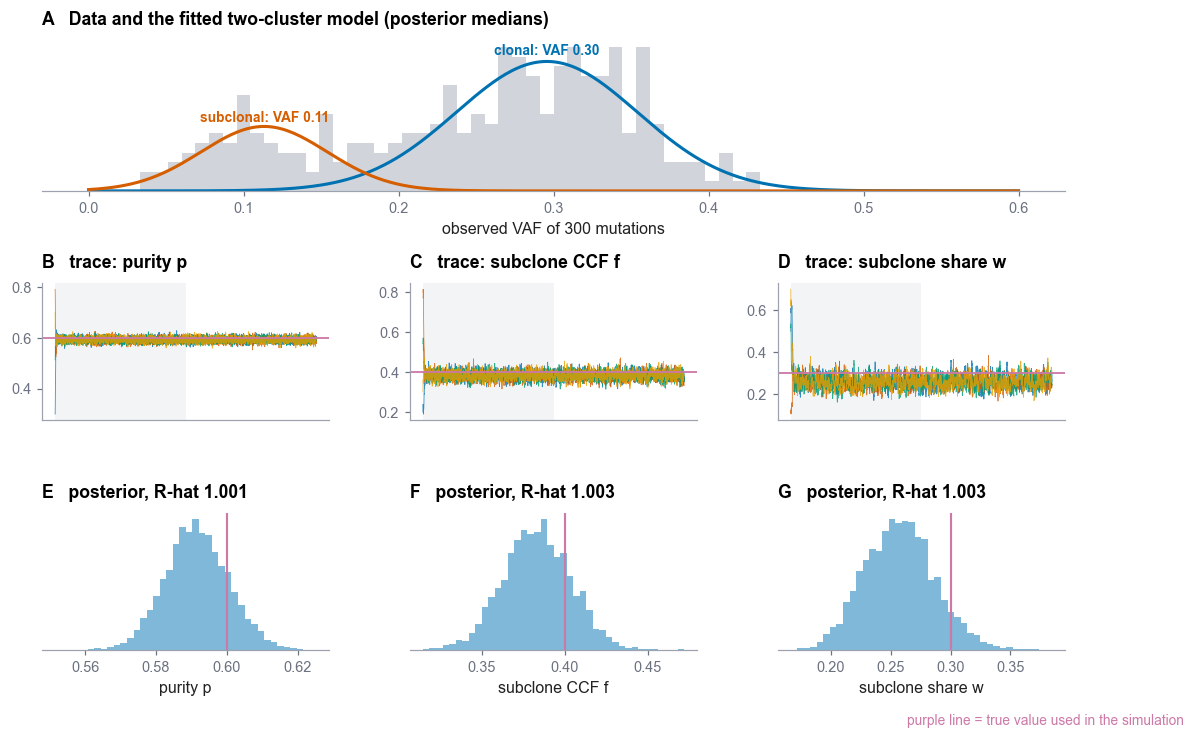

purity          median 0.591  95% [0.575, 0.610]  R-hat 1.001
subclone CCF    median 0.383  95% [0.344, 0.423]  R-hat 1.003
subclone share  median 0.257  95% [0.202, 0.318]  R-hat 1.003
acceptance per chain: ['34%', '34%', '34%', '35%']


In [12]:
lp_mix = make_logpost_mix(alt, dp)
chains, accs = [], []
for i, start in enumerate([(0.3, 0.2, 0.5), (0.8, 0.8, 0.1), (0.5, 0.5, 0.5), (0.7, 0.3, 0.7)]):
    ch, a_ = metropolis_nd(lp_mix, logit(np.array(start)), step=0.08, n_iter=12000, rng=np.random.default_rng(100 + i))
    chains.append(expit(ch)); accs.append(a_)
keep_mix = draw_mix_results(alt, dp, chains, truth=(0.6, 0.4, 0.3))
med = np.median(keep_mix, axis=0); lo, hi = np.quantile(keep_mix, [0.025, 0.975], axis=0)
rh = [split_rhat(np.array([c[:, j] for c in chains])) for j in range(3)]
for j, name in enumerate(["purity", "subclone CCF", "subclone share"]):
    print(f"{name:15s} median {med[j]:.3f}  95% [{lo[j]:.3f}, {hi[j]:.3f}]  R-hat {rh[j]:.3f}")
print("acceptance per chain:", [f"{a_:.0%}" for a_ in accs])
assert all(r < 1.01 for r in rh)                              # Vehtari 외 2021 의 기준
assert all(lo[j] < t < hi[j] for j, t in enumerate((0.6, 0.4, 0.3)))

**그림에서 볼 것**
- A: 변이 300 개의 VAF 히스토그램(회색) 위에 사후 중앙값으로 그린 두 봉우리입니다. 파랑이 클론성(VAF ≈ 0.30 = purity 0.6 의 절반), 빨강이 subclone(VAF ≈ 0.11)입니다. 그림 속 숫자는 사후 중앙값으로 계산한 값입니다.
- B–D: 네 사슬(색)이 서로 다른 출발점에서 시작해 몇백 걸음 안에 같은 띠로 모입니다. 옅은 회색은 warm-up, 자주색 선은 진짜 값입니다.
- E–G: warm-up 을 버린 사후입니다. 세 모수 모두 95% 구간이 진짜 값을 포함하고, $\hat R$ 이 1 에 가깝습니다(위 출력). purity 사후가 가장 좁은 것은 변이의 70% 가 클론 봉우리에 있어서입니다.

**직접 바꿔 보기**: `simulate_vaf(depth=20)` 처럼 깊이를 낮추거나 `ccf_sub=0.8` 로 subclone 을 클론 봉우리에 가깝게 두면, f 와 w 의 사후가 넓어지고 서로 얽힙니다. 실제 데이터에서 subclone 판정이 어려운 경우가 이렇습니다.

In [13]:
# alt20, dp20, _ = simulate_vaf(depth=20, ccf_sub=0.8, seed=1)
# lp20 = make_logpost_mix(alt20, dp20)
# ch20 = [expit(metropolis_nd(lp20, logit(np.array(s)), 0.08, 6000, np.random.default_rng(i))[0]) for i, s in enumerate([(0.3, 0.2, 0.5), (0.8, 0.9, 0.1), (0.5, 0.5, 0.5), (0.7, 0.3, 0.7)])]
# draw_mix_results(alt20, dp20, ch20, truth=(0.6, 0.8, 0.3))

> **시퀀싱 데이터에서는**: purity·CCF·군집을 함께 추정하는 clonality 도구, 시점 추정(MutationTimeR), signature 노출량의 불확실성처럼 모수가 많은 문제는 대부분 MCMC 나 그 변형으로 사후를 구합니다. 결과를 받을 때 trace 와 $\hat R$ 같은 진단을 함께 보는 습관이 필요합니다. Gerstung 2020 의 실시간 추정도 위계적 베이지안 회귀를 Hamiltonian Monte Carlo 로 추정했다고 적습니다 [10].

## 연습 문제

1. 지금 θ = 0.30 에서 후보 θ* = 0.20 이 나왔습니다(6/20, 평평한 사전). r 은 얼마이고, 받아들일 확률은?
2. 모수 5 개를 각 50 칸 격자로 계산하면 점이 몇 개입니까?
3. 사슬 4 개의 $\hat R$ 이 1.4 로 나왔습니다. 무엇을 해야 합니까?
4. 7 절에서 logit 눈금으로 걸을 때 야코비안 항을 빼먹으면 사전이 어떻게 바뀌는 셈일까요?

<details><summary>정답 보기</summary>

1. $r = (0.2^6 0.8^{14})/(0.3^6 0.7^{14}) \approx 0.57$, 받아들일 확률 0.57.
2. $50^5 \approx 3.1\times10^8$ 개.
3. 아직 섞이지 않았습니다. 더 오래 돌리거나 걸음 크기를 바꾸고, 출발점에 따라 다른 봉우리에 갇히지 않았는지 trace 를 봅니다. BDA3 는 R̂ 이 1 근처가 될 때까지 시뮬레이션을 이어 가라고 합니다.
4. logit 눈금에서 평평한 사전이 됩니다. 원래 눈금으로는 0 과 1 근처에 무게를 크게 두는 사전(Beta(0, 0) 꼴에 가까움)이라 결과가 달라질 수 있습니다.

</details>

In [14]:
a1 = np.exp(logpost_vaf(0.20) - logpost_vaf(0.30))
print(f"1: r = {a1:.3f};  2: {50 ** 5:,}")
assert abs(a1 - 0.57) < 0.01 and 50 ** 5 == 312_500_000

1: r = 0.569;  2: 312,500,000


## 정리

- 모수가 한두 개면 격자 근사가 가장 쉽습니다. 격자가 너무 성기면 사후가 왜곡됩니다.
- 모수마다 100 칸이면 격자 점은 $100^d$ 개라, 모수가 늘면 불가능해집니다.
- Metropolis 는 후보를 제안하고 사후 높이의 비 r 로 받거나 거절합니다. 증거 $p(y)$ 가 지워져서 사전 × 우도만 있으면 됩니다.
- 걸음이 너무 작으면 느리고, 너무 크면 제자리입니다. 앞쪽 절반(warm-up)은 버립니다.
- 출발점을 흩어 놓은 여러 사슬과 $\hat R$ 으로 섞임을 확인합니다. 1 에 가까워야 합니다.
- purity, subclone CCF, subclone 비율을 함께 추정하는 것이 clonality 분석의 가장 작은 판입니다.

다음 노트북(P9)에서는 이 도구들을 실제 시퀀싱 도구들의 계산(genotype 호출, 체세포 판정, CCF, 증폭 시점, PURPLE clonality)에 하나씩 대어 봅니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Gelman A 외. *Bayesian Data Analysis*, 3rd ed. 비상업용 PDF: [책 누리집](https://sites.stat.columbia.edu/gelman/book/) | 2.4 절 끝 격자 근사 경고, 11.2 절 Metropolis 단계와 식 (11.1), 좋은 제안 분포의 조건, 정상 분포 논증, 11.4 절 warm-up(앞쪽 절반), B·W·var⁺·$\hat R$ 식, 사슬 나누기, 11.5 절(pp.287–288) "1.1 as a threshold"·유효 표본 수·"R̂ 1 근처·유효 표본 사슬당 10", 12.2 절(p.296) $c \approx 2.4/\sqrt d$, 효율 약 $0.3/d$, 받아들임 비율 0.44(1 차원)·0.23(고차원) |
| [2] | Metropolis N, Rosenbluth AW, Rosenbluth MN, Teller AH, Teller E. 1953. Equation of State Calculations by Fast Computing Machines. *J Chem Phys* 21:1087–1092. [doi:10.1063/1.1699114](https://doi.org/10.1063/1.1699114) | 알고리즘의 원 논문(서지 정보만 확인) |
| [3] | Gelman A, Rubin DB. 1992. Inference from Iterative Simulation Using Multiple Sequences. *Statist Sci* 7:457–472. [doi:10.1214/ss/1177011136](https://doi.org/10.1214/ss/1177011136) | 여러 사슬 진단의 원 논문(서지 정보만 확인) |
| [4] | Vehtari A, Gelman A, Simpson D, Carpenter B, Bürkner PC. 2021. Rank-Normalization, Folding, and Localization: An Improved R̂ for Assessing Convergence of MCMC. *Bayesian Anal* 16:667–718. [doi:10.1214/20-BA1221](https://doi.org/10.1214/20-BA1221), [arXiv:1903.08008](https://arxiv.org/abs/1903.08008) | 4 쪽 "only using the sample if R̂ < 1.01", "at least four chains by default", 5 쪽 순위 정규화 유효 표본 수 > 400 |
| [5] | McElreath R. *Statistical Rethinking* 2023, [GitHub 강의표](https://github.com/rmcelreath/stat_rethinking_2023) 8강 "MCMC" | 같이 볼 강의 |
| [6] | Downey AB. *Think Bayes* 2nd ed., [19장 MCMC](https://allendowney.github.io/ThinkBayes2/chap19.html) | 같이 볼 교재 |
| [7] | Blitzstein J. Harvard Statistics 110 [31강 "Markov Chains"](https://www.youtube.com/watch?v=8AJPs3gvNlY) ~ 33강 ([재생목록](https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo)) | 마르코프 연쇄 기초 |
| [8] | Dentro SC 외. 2021. Characterizing genetic intra-tumor heterogeneity across 2,658 human cancer genomes. *Cell* 184(8):2239–2254.e39. [doi:10.1016/j.cell.2021.03.009](https://doi.org/10.1016/j.cell.2021.03.009), [PMC8054914](https://pmc.ncbi.nlm.nih.gov/articles/PMC8054914/) | STAR Methods(BayClone-C 설명)의 VAF 식, 변이 copy 수 $CN_M$ |
| [9] | 같은 논문 [8], STAR Methods "PhylogicNDT" | ABSOLUTE 의 변이별 CCF 분포 + Dirichlet Process 군집 |
| [10] | Gerstung M 외. 2020. The evolutionary history of 2,658 cancers. *Nature* 578:122–128. [doi:10.1038/s41586-019-1907-7](https://doi.org/10.1038/s41586-019-1907-7), [PMC7054212](https://pmc.ncbi.nlm.nih.gov/articles/PMC7054212/) | Extended Data 그림 설명: 위계적 베이지안 회귀, Hamiltonian Monte Carlo |

격자·MCMC 결과, 시간 측정, 장난감 VAF 모형의 숫자는 이 노트북에서 직접 계산한 결과입니다.